Generated airfoil parameters: 
Maximum camber=  5.85%
Position of maximum camber=  42.46%chord
Maximum thickness =  9.79% chord


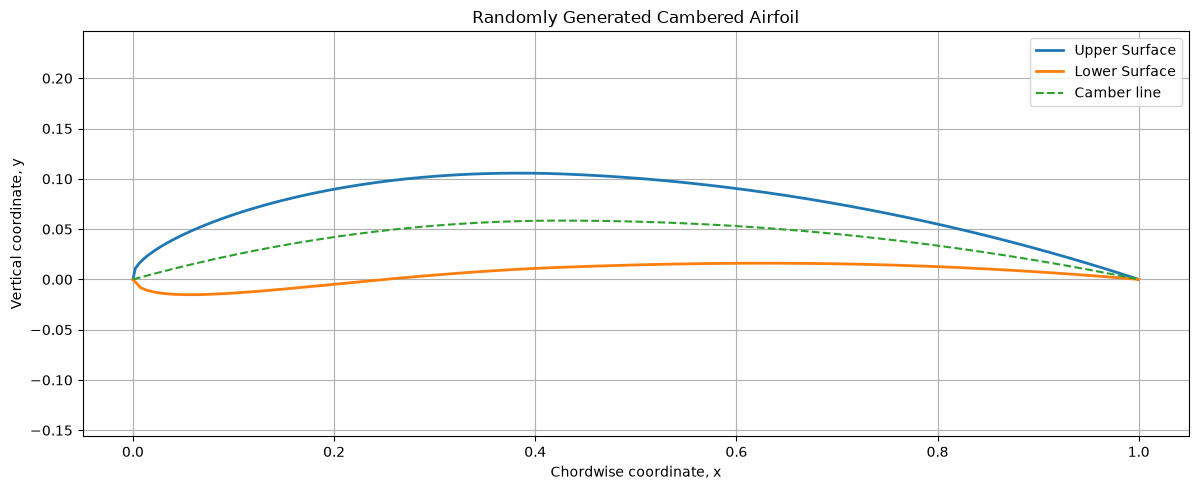

C:\Users\abhis\AppData\Local\Temp\ipykernel_15848\2202271968.py:99: DeprecationWarning: `lagrange` is deprecated and will be removed in SciPy 1.20.0. Use `scipy.interpolate.BarycentricInterpolator` instead.
  poly_upper = scipy_lagrange(xud, yud)
C:\Users\abhis\AppData\Local\Temp\ipykernel_15848\2202271968.py:100: DeprecationWarning: `lagrange` is deprecated and will be removed in SciPy 1.20.0. Use `scipy.interpolate.BarycentricInterpolator` instead.
  poly_lower = scipy_lagrange(xld, yld)



Verification against SciPy:
Upper surface maximum difference: 1.9306158004223079e-10
Lower surface maximum difference: 1.966576768235862e-10

Reconstruction errors:
Maximum absolute error: 8.98588262e-03
RMS error: 1.07425024e-03


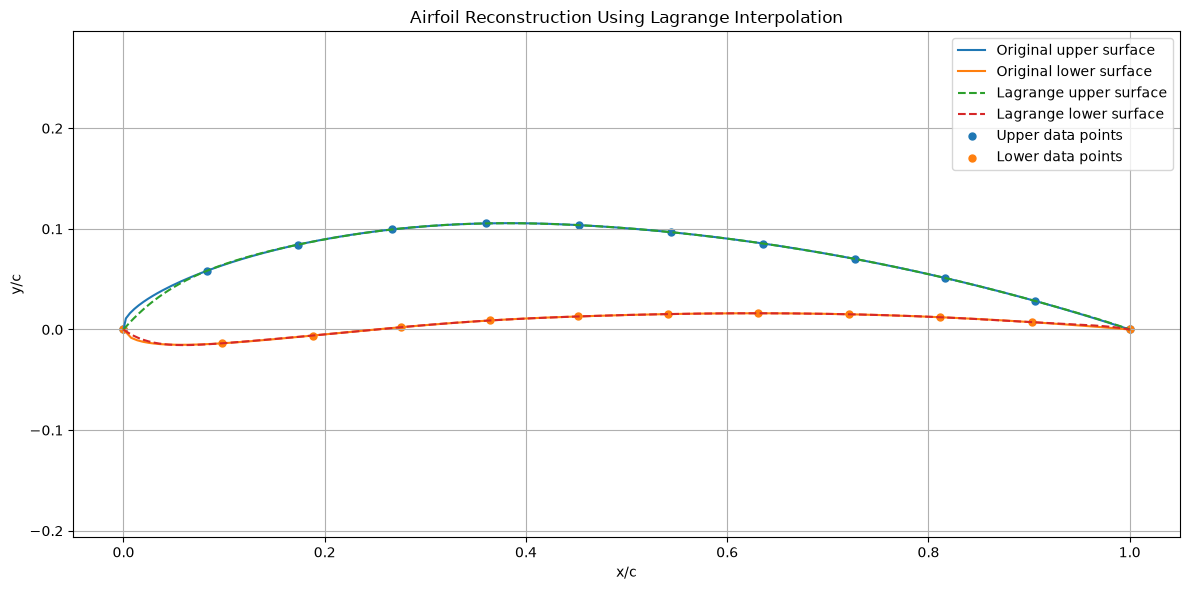


Original points: 200
Selected interpolation points: 12
Selected indices: [  0  18  36  54  72  90 108 126 144 162 180 199]

Verification of Lagrange function against SciPy
Upper x max difference: 3.114218998234719e-07
Upper y max difference: 3.405899563711795e-08
Lower x max difference: 8.502963211309833e-08
Lower y max difference: 4.190138027646062e-09

Cubic Spline Reconstruction Errors:
Maximum absolute error: 2.83825831e-03
RMS error:              8.07908168e-04


C:\Users\abhis\AppData\Local\Temp\ipykernel_15848\2202271968.py:235: DeprecationWarning: `lagrange` is deprecated and will be removed in SciPy 1.20.0. Use `scipy.interpolate.BarycentricInterpolator` instead.
  np.max(np.abs(xu_lag - scipy_lagrange(u_data, xu_data)(uu))))
C:\Users\abhis\AppData\Local\Temp\ipykernel_15848\2202271968.py:237: DeprecationWarning: `lagrange` is deprecated and will be removed in SciPy 1.20.0. Use `scipy.interpolate.BarycentricInterpolator` instead.
  np.max(np.abs(yu_lag - scipy_lagrange(u_data, yu_data)(uu))))
C:\Users\abhis\AppData\Local\Temp\ipykernel_15848\2202271968.py:239: DeprecationWarning: `lagrange` is deprecated and will be removed in SciPy 1.20.0. Use `scipy.interpolate.BarycentricInterpolator` instead.
  np.max(np.abs(xl_lag - scipy_lagrange(u_data, xl_data)(uu))))
C:\Users\abhis\AppData\Local\Temp\ipykernel_15848\2202271968.py:241: DeprecationWarning: `lagrange` is deprecated and will be removed in SciPy 1.20.0. Use `scipy.interpolate.Barycentri

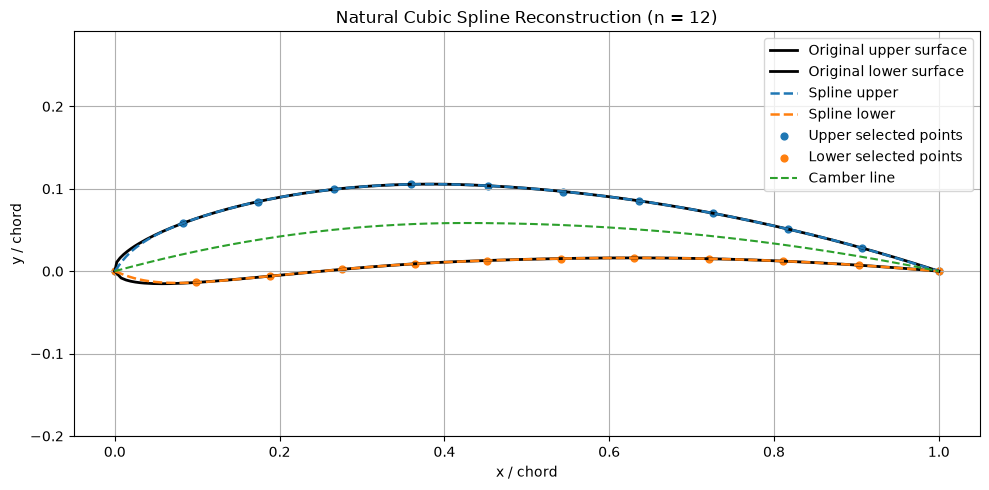

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import lagrange as scipy_lagrange

rng=np.random.default_rng()  #This will help me to pick a number for generating random number within the specified range for the airfoil parameters

#The numbers will be picked up from the below range
m_rng= (0.00, 0.06)
p_rng= (0.20, 0.60)
t_rng= (0.06, 0.18)

m=rng.uniform(*m_rng)
p=rng.uniform(*p_rng)
t=rng.uniform(*t_rng)

print("Generated airfoil parameters: ")
print(f"Maximum camber= {100*m: .2f}%")
print(f"Position of maximum camber= {100*p: .2f}%chord")
print(f"Maximum thickness = {100*t: .2f}% chord")

# Now let's define chord length and number of points (As discussed in the class we'll not have any input function, hence we'll used a number beforehand)

c=1.0 # we'll define the range of chord from 0 to 1 because whatever parameters that we take are with respect to chord, i.e in percentage of chord
N=200

x=np.linspace(0,c,N) #creates equally spaced points within the chord range
xc= x/c              # Normalising the coordinates with respect to the chord

yc=np.zeros(N)
dyc_dx=np.zeros(N)

for i in range(N):
  if xc[i]<p:
    yc[i] = (m/p**2)*(2*p*xc[i]-xc[i]**2)
    dyc_dx[i] = (2*m/p**2)*(p-xc[i])

  else:
    yc[i] = (m/(1-p)**2) * ((1-2*p) + 2*p*xc[i] - xc[i]**2)
    dyc_dx[i] = (2*m/(1-p)**2) * (p-xc[i])

yt=5*t*(0.2969*np.sqrt(xc)-0.1260*xc-0.3516*xc**2+0.2843*xc**3-0.1036*xc**4) #formula taken from Wikipedia

theta=np.arctan(dyc_dx)

xu = x - yt*np.sin(theta)*c
yu = yc*c + yt*np.cos(theta)*c

xl= x + yt*np.sin(theta)*c
yl= yc*c - yt*np.cos(theta)*c

plt.figure(figsize=(12,5))

plt.plot(xu,yu, label= "Upper Surface", linewidth =2)
plt.plot(xl,yl, label="Lower Surface", linewidth =2)
plt.plot(x,yc*c, "--", label="Camber line")

plt.xlabel("Chordwise coordinate, x")
plt.ylabel("Vertical coordinate, y")
plt.title("Randomly Generated Cambered Airfoil")

plt.axis("equal")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

def Lagrng(x, y, n, xx):
    total = np.zeros_like(np.asarray(xx, dtype=float))

    for i in range(n):
        product = y[i]

        for j in range(n):
            if i != j:
                product = product * (
                    (xx - x[j]) / (x[i] - x[j])
                )

        total = total + product

    return total


n = 12

indices = np.linspace(0, N - 1, n, dtype=int)
yld = yl[indices]

xud = xu[indices]
yud = yu[indices]

xld = xl[indices]

xx = np.linspace(0, 1, 400)

yu_lagrange = Lagrng(xud, yud, n, xx)
yl_lagrange = Lagrng(xld, yld, n, xx)

poly_upper = scipy_lagrange(xud, yud)
poly_lower = scipy_lagrange(xld, yld)

yu_scipy = poly_upper(xx)
yl_scipy = poly_lower(xx)

print("\nVerification against SciPy:")
print("Upper surface maximum difference:",
      np.max(np.abs(yu_lagrange - yu_scipy)))
print("Lower surface maximum difference:",
      np.max(np.abs(yl_lagrange - yl_scipy)))

#Calculating error for Lagrange interpolation
yu_true = np.interp(xx, xu, yu)
yl_true = np.interp(xx, xl, yl)

upper_error = yu_true - yu_lagrange
lower_error = yl_true - yl_lagrange

max_error = max(
    np.max(np.abs(upper_error)),
    np.max(np.abs(lower_error))
)

rms_error = np.sqrt(
    np.mean(np.concatenate([
        upper_error**2,
        lower_error**2
    ]))
)

print("\nReconstruction errors:")
print(f"Maximum absolute error: {max_error:.8e}")
print(f"RMS error: {rms_error:.8e}")

plt.figure(figsize=(12, 6))

plt.plot(xu, yu, label="Original upper surface")
plt.plot(xl, yl, label="Original lower surface")

plt.plot(xx, yu_lagrange, "--",
         label="Lagrange upper surface")
plt.plot(xx, yl_lagrange, "--",
         label="Lagrange lower surface")

plt.scatter(xud, yud, s=25, label="Upper data points")
plt.scatter(xld, yld, s=25, label="Lower data points")

plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title("Airfoil Reconstruction Using Lagrange Interpolation")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

#cubic spline function

def cubic_spline(x_data, y_data, xx):
    """
    Natural cubic spline interpolation.
    The second derivative is zero at both endpoints.
    """
    x_data = np.asarray(x_data, dtype=float)
    y_data = np.asarray(y_data, dtype=float)
    xx = np.asarray(xx, dtype=float)

    n_points = len(x_data)
    if n_points < 2:
        raise ValueError("At least two data points are required.")
    if len(y_data) != n_points:
        raise ValueError("x_data and y_data must have equal lengths.")
    if np.any(np.diff(x_data) <= 0):
        raise ValueError("x_data must be strictly increasing.")

    h = np.diff(x_data)
    A = np.zeros((n_points, n_points))
    rhs = np.zeros(n_points)

    A[0, 0] = 1.0
    A[-1, -1] = 1.0

    for i in range(1, n_points - 1):
        A[i, i-1] = h[i-1]
        A[i, i] = 2.0 * (h[i-1] + h[i])
        A[i, i+1] = h[i]
        rhs[i] = 6.0 * (
            (y_data[i+1] - y_data[i]) / h[i]
            - (y_data[i] - y_data[i-1]) / h[i-1]
        )

    M = np.linalg.solve(A, rhs)

    interval = np.searchsorted(x_data, xx, side="right") - 1
    interval = np.clip(interval, 0, n_points - 2)

    left = x_data[interval]
    right = x_data[interval + 1]
    hi = right - left

    term1 = M[interval] * (right - xx)**3 / (6.0 * hi)
    term2 = M[interval + 1] * (xx - left)**3 / (6.0 * hi)
    term3 = (
        y_data[interval] - M[interval] * hi**2 / 6.0
    ) * (right - xx) / hi
    term4 = (
        y_data[interval + 1] - M[interval + 1] * hi**2 / 6.0
    ) * (xx - left) / hi

    return term1 + term2 + term3 + term4

indices = np.linspace(0, N - 1, n, dtype=int)

u = np.sqrt(x / c)
u_data = u[indices]

xx = np.linspace(0.0, c, 1000)
uu = np.sqrt(xx / c)

xu_data = xu[indices]
yu_data = yu[indices]
xl_data = xl[indices]
yl_data = yl[indices]

print(f"\nOriginal points: {N}")
print(f"Selected interpolation points: {n}")
print("Selected indices:", indices)

xu_lag = Lagrng(u_data, xu_data, n, uu)
yu_lag = Lagrng(u_data, yu_data, n, uu)
xl_lag = Lagrng(u_data, xl_data, n, uu)
yl_lag = Lagrng(u_data, yl_data, n, uu)

print("\nVerification of Lagrange function against SciPy")
print("Upper x max difference:",
      np.max(np.abs(xu_lag - scipy_lagrange(u_data, xu_data)(uu))))
print("Upper y max difference:",
      np.max(np.abs(yu_lag - scipy_lagrange(u_data, yu_data)(uu))))
print("Lower x max difference:",
      np.max(np.abs(xl_lag - scipy_lagrange(u_data, xl_data)(uu))))
print("Lower y max difference:",
      np.max(np.abs(yl_lag - scipy_lagrange(u_data, yl_data)(uu))))

xu_spl = cubic_spline(u_data, xu_data, uu)
yu_spl = cubic_spline(u_data, yu_data, uu)
xl_spl = cubic_spline(u_data, xl_data, uu)
yl_spl = cubic_spline(u_data, yl_data, uu)


#calculating the error for cubic spline interpolation

yu_true_spline = np.interp(xx, xu, yu)
yl_true_spline = np.interp(xx, xl, yl)

upper_error_spline = yu_true_spline - yu_spl
lower_error_spline = yl_true_spline - yl_spl


max_error_spline = max(
    np.max(np.abs(upper_error_spline)),
    np.max(np.abs(lower_error_spline))
)

rms_error_spline = np.sqrt(
    np.mean(np.concatenate([
        upper_error_spline**2,
        lower_error_spline**2
    ]))
)

print("\nCubic Spline Reconstruction Errors:")
print(f"Maximum absolute error: {max_error_spline:.8e}")
print(f"RMS error:              {rms_error_spline:.8e}")


plt.figure(figsize=(10, 5))
plt.plot(xu, yu, "k-", linewidth=2, label="Original upper surface")
plt.plot(xl, yl, "k-", linewidth=2, label="Original lower surface")
plt.plot(xu_spl, yu_spl, "--", linewidth=1.8, label="Spline upper")
plt.plot(xl_spl, yl_spl, "--", linewidth=1.8, label="Spline lower")
plt.scatter(xu_data, yu_data, s=24, label="Upper selected points")
plt.scatter(xl_data, yl_data, s=24, label="Lower selected points")
plt.xlabel("x / chord")
plt.ylabel("y / chord")
plt.plot(x,yc*c, "--", label="Camber line")
plt.title(f"Natural Cubic Spline Reconstruction (n = {n})")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
